<a href="https://colab.research.google.com/github/byhringjstudent/Google-Colab-MWERA-Presentation/blob/main/FINAL_Student_Success_and_Scholarship_Research_and_Report_for_MWERA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Title: #

### Expressive Python:  Applying Python to Educational and Scientific Data #



# Listing of Presenters and Roles: #

### Jason Byhring #
### Master of Science in Education (M.S.Ed) in Instructional Technology #


In [5]:
!pip install pyreadstat
!pip install pandas
!pip install numpy
!pip install matplotlib
!pip install matplotlib.pyplot as plt
!pip install scipy
!pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 32.4 MB/s eta 0:00:00
ERROR: Could not find a version that satisfies the requirement matplotlib.pyplot (from versions: none)
ERROR: No matching distribution found for matplotlib.pyplot


## Understanding the Pandas Library: ##

### Pandas is an open-source Python package that is most widely used for scientific analysis and machine learning tasks. ###

In [41]:
import pandas as pd
import pyreadstat

# WORKSHOP INSTRUCTION:

# To load SPSS data in Python, we use pyreadstat.read_sav().
# This returns two critical items:
# 1) 'df' - a standard Pandas DataFrame containing your numeric and text data matrix.
# 2) 'meta' - a rich metadata object holding variable labels, original value maps, and survey structures.
df, meta = pyreadstat.read_sav("mwera_student_academic_success_dataset.sav")

## Part 2: Inspect/Clean Data ##


In [43]:
# WORKSHOP INSTRUCTION:

# 'df.head()' is a highly useful Pandas method that returns the first 5 rows of your DataFrame by default.
# It allows you to quickly inspect the structure of your newly loaded dataset, check the column names,
# and verify that the data has been loaded correctly with the expected formatting.
df.head()

,student_id,age,gener,race_ethnicity,major,gpa,study_hours,attendance_rate,num_courses,first_gen,scholarship,graduation_intent,sat_score,employed
0,100001.0,21.0,Male,Asian,Undeclared,2.89,17.0,94.9,4.0,1.0,1.0,4.0,1320.0,0.0
1,100002.0,21.0,Male,Native American or Alaska Native,Engineering,3.72,22.2,100.0,2.0,0.0,0.0,5.0,1250.0,1.0
2,100003.0,18.0,Female,Asian,Sociology,3.02,18.2,88.8,5.0,0.0,0.0,4.0,1100.0,0.0
3,100004.0,25.0,Male,Hispanic or Latino,Education,2.38,22.3,87.6,3.0,0.0,1.0,3.0,830.0,1.0
4,100005.0,23.0,Male,Black or African American,Education,2.69,23.0,87.1,4.0,0.0,0.0,5.0,1030.0,1.0


In [44]:
# WORKSHOP INSTRUCTION:

# 'df.shape' is a Pandas attribute that returns a tuple representing the dimensions of your DataFrame.
# The first value represents the total number of rows (observations), and the second value represents
# the total number of columns (variables) in the dataset.

# Note: Since it is an attribute and not a method, it does not require parentheses ().
df.shape

(250, 14)

In [45]:
# WORKSHOP INSTRUCTION:

# 'df.columns' is a Pandas attribute that retrieves a list of all column headers (variable names)
# in your DataFrame. This is useful for checking which variables are available for analysis
# or verifying column name formatting.

# Note: As an attribute, it does not require parentheses ().
df.columns

Index(['student_id', 'age', 'gener', 'race_ethnicity', 'major', 'gpa',
       'study_hours', 'attendance_rate', 'num_courses', 'first_gen',
       'scholarship', 'graduation_intent', 'sat_score', 'employed'],
      dtype='object')

In [48]:
# WORKSHOP INSTRUCTION:

# Often you only need the metadata structure of an SPSS file rather than importing the whole dataset.
# By using '_, meta = pyreadstat.read_sav(...)', we discard the heavy DataFrame (using the underscore '_')
# and quickly extract only the 'meta' object.
# We then access 'meta.column_names' to retrieve a list of all variable names in the dataset.

# Load the metadata of the SAV file to define 'meta' object
_, meta = pyreadstat.read_sav('mwera_student_academic_success_dataset.sav')

# Now we can retrieve the list of column names
meta.column_names

['student_id',
 'age',
 'gener',
 'race_ethnicity',
 'major',
 'gpa',
 'study_hours',
 'attendance_rate',
 'num_courses',
 'first_gen',
 'scholarship',
 'graduation_intent',
 'sat_score',
 'employed']

In [47]:
# WORKSHOP INSTRUCTION:

# Categorical survey variables in SPSS are stored numerically (e.g., 0.0, 1.0).
# Use 'meta.variable_value_labels' to retrieve the dictionary mapping these numeric codes
# back to their human-readable category labels (like {0.0: 'No', 1.0: 'Yes'}).
meta.variable_value_labels

{'first_gen': {0.0: 'No', 1.0: 'Yes'},
 'scholarship': {0.0: 'No', 1.0: 'Yes'},
 'graduation_intent': {1.0: 'Very unlikely',
  2.0: 'Unlikely',
  3.0: 'Unsure',
  4.0: 'Likely',
  5.0: 'Very likely'},
 'employed': {0.0: 'No', 1.0: 'Yes'}}

## Part 3:  Summarizing Data ##

In [50]:
# WORKSHOP INSTRUCTION:

# 'df.describe()' is a highly useful Pandas method that generates descriptive statistics
# of your dataset's numeric columns.
# It provides key metrics such as the count of non-missing values, mean, standard deviation (std),
# minimum, maximum, and the 25th, 50th (median), and 75th percentiles.
df.describe()

,student_id,age,gpa,study_hours,attendance_rate,num_courses,first_gen,scholarship,graduation_intent,sat_score,employed
count,250.000000,250.00000,250.000000,250.000000,250.00000,250.00000,250.000000,250.0000,250.000000,250.000000,250.000000
mean,100125.500000,21.54400,3.162960,21.305600,88.07880,4.38800,0.364000,0.2800,4.308000,1147.720000,0.456000
std,72.312977,2.92477,0.441305,5.868065,7.84018,0.90816,0.482114,0.4499,0.774296,146.380705,0.499059
min,100001.000000,18.00000,1.750000,6.100000,67.80000,2.00000,0.000000,0.0000,2.000000,820.000000,0.000000
25%,100063.250000,19.00000,2.852500,17.400000,82.90000,4.00000,0.000000,0.0000,4.000000,1060.000000,0.000000
50%,100125.500000,21.00000,3.165000,21.600000,87.95000,4.00000,0.000000,0.0000,4.000000,1145.000000,0.000000
75%,100187.750000,24.00000,3.480000,25.300000,94.40000,5.00000,1.000000,1.0000,5.000000,1240.000000,1.000000
max,100250.000000,32.00000,4.000000,38.000000,100.00000,6.00000,1.000000,1.0000,5.000000,1520.000000,1.000000


In [56]:
# Pandas method is useful in that it counts the frequency of unique row combinations
# across your DataFrame.
df.value_counts()

,,,,,,,,,,,,,,count
student_id,age,gener,race_ethnicity,major,gpa,study_hours,attendance_rate,num_courses,first_gen,scholarship,graduation_intent,sat_score,employed,
100001.0,21.0,Male,Asian,Undeclared,2.89,17.0,94.9,4.0,1.0,1.0,4.0,1320.0,0.0,1
100002.0,21.0,Male,Native American or Alaska Native,Engineering,3.72,22.2,100.0,2.0,0.0,0.0,5.0,1250.0,1.0,1
100003.0,18.0,Female,Asian,Sociology,3.02,18.2,88.8,5.0,0.0,0.0,4.0,1100.0,0.0,1
100004.0,25.0,Male,Hispanic or Latino,Education,2.38,22.3,87.6,3.0,0.0,1.0,3.0,830.0,1.0,1
100005.0,23.0,Male,Black or African American,Education,2.69,23.0,87.1,4.0,0.0,0.0,5.0,1030.0,1.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100246.0,18.0,Male,White,Computer Science,3.49,34.4,87.6,4.0,0.0,1.0,5.0,1260.0,0.0,1
100247.0,19.0,Male,White,Education,3.70,29.5,89.7,5.0,1.0,0.0,5.0,1160.0,0.0,1
100248.0,23.0,Female,Black or African American,Computer Science,3.64,33.8,100.0,5.0,0.0,0.0,5.0,1210.0,0.0,1


In [57]:
# WORKSHOP INSTRUCTION:
# 'df.value_counts()' is a Pandas method that counts the frequency of unique row combinations
# across your DataFrame.
# When applied to the entire DataFrame, it identifies completely unique records. Since every student
# in this dataset has a unique ID, each combination of columns appears exactly once (count of 1).
# Note: To get categorical frequency counts, you normally apply this to a single column
# (e.g., df['major'].value_counts()).

df.value_counts()
df['gpa'].value_counts()

,count
gpa,
4.00,7
3.33,5
3.08,4
3.54,4
3.48,4
...,...
2.67,1
3.52,1
3.45,1


In [58]:
# WORKSHOP INSTRUCTION:

# The 'df.groupby()' method in Pandas is used to split a DataFrame into groups based on one or more variables.
# Once grouped, we can isolate a specific column—like ['gpa']—and apply an aggregation function like '.mean()'.
# This follows the standard Split-Apply-Combine workflow:
# 1) Split: Group the dataset by each unique value of 'study_hours'.
# 2) Apply: Calculate the average (arithmetic mean) GPA for each study hour group.
# 3) Combine: Merge these individual group averages into a single, clean Pandas Series.

mean_gpa = df.groupby('study_hours')['gpa'].mean()
print(mean_gpa)

study_hours
6.1     3.08
7.8     2.86
8.6     1.75
9.1     2.98
9.4     2.75
        ... 
33.8    3.64
34.4    3.49
35.1    3.94
35.9    2.93
38.0    3.35
Name: gpa, Length: 160, dtype: float64


In [60]:
# WORKSHOP INSTRUCTION:

# We can group by categorical variables—like 'graduation_intent' (stored as 1.0 to 5.0)—
# to analyze how numeric outcomes like study hours and GPA differ across those groups.
# By passing a list of columns ['gpa', 'study_hours'] to our grouped data,
# we can calculate both averages simultaneously.

# Group by graduation intent and calculate the average GPA and study hours for each group
intent_comparison = df.groupby('graduation_intent')[['gpa', 'study_hours']].mean()
display(intent_comparison)

,gpa,study_hours
graduation_intent,,
2.0,2.526667,15.800000
3.0,2.769333,18.320000
4.0,3.109158,20.365263
5.0,3.337227,23.086555


In [61]:
# WORKSHOP INSTRUCTION:

# The 'df.sort_values()' method allows us to reorder our DataFrame rows based on a specified column.

# Parameters:
# 1) 'by' - the target column used to determine the sorted order (e.g., 'study_hours').
# 2) 'ascending=False' - sorts the data in descending order (highest to lowest).
# This allows us to quickly identify top outliers, such as the students with the highest study hours.

df.sort_values(by='study_hours', ascending=False)

,student_id,age,gener,race_ethnicity,major,gpa,study_hours,attendance_rate,num_courses,first_gen,scholarship,graduation_intent,sat_score,employed
188,100189.0,21.0,Female,Prefer not to say,Nursing,3.35,38.0,80.9,5.0,0.0,0.0,5.0,1120.0,0.0
79,100080.0,18.0,Female,Hispanic or Latino,Business Administration,2.93,35.9,84.5,4.0,1.0,0.0,5.0,1010.0,1.0
164,100165.0,25.0,Male,Asian,Criminal Justice,3.94,35.1,82.8,5.0,1.0,0.0,5.0,1130.0,0.0
245,100246.0,18.0,Male,White,Computer Science,3.49,34.4,87.6,4.0,0.0,1.0,5.0,1260.0,0.0
247,100248.0,23.0,Female,Black or African American,Computer Science,3.64,33.8,100.0,5.0,0.0,0.0,5.0,1210.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
165,100166.0,18.0,Male,White,Nursing,2.75,9.4,92.1,3.0,1.0,0.0,3.0,1300.0,1.0
121,100122.0,19.0,Female,Asian,Criminal Justice,2.98,9.1,80.4,3.0,0.0,0.0,4.0,1130.0,0.0
122,100123.0,19.0,Nonbinary,White,Computer Science,1.75,8.6,68.3,4.0,0.0,0.0,3.0,820.0,1.0
150,100151.0,25.0,Female,White,Business Administration,2.86,7.8,89.4,3.0,0.0,0.0,4.0,1220.0,0.0


In [62]:
# WORKSHOP INSTRUCTION:

# The 'df.std()' method calculates the sample standard deviation for your dataset's columns,
# which measures the spread of your observations around their mean.
#
# Parameter:
# - 'numeric_only=True': Restricts the calculation to numeric columns (floats, integers, booleans),
#   preventing potential errors from categorical text columns like gender, race, or major.

df.std(numeric_only=True)

,0
student_id,72.312977
age,2.924770
gpa,0.441305
study_hours,5.868065
attendance_rate,7.840180
num_courses,0.908160
first_gen,0.482114
scholarship,0.449900
graduation_intent,0.774296
sat_score,146.380705


## Part 4:  Data Visualization ##

#### Understanding the Matplotlib library for educational statistics:

#### Matplotlib are the foundational data visualization libraries in Python.  In structural terms, the figure or statistic graphic is the most important feature and building block of this library, allowing you to easily transform complex arrays and DataFrames into clear, interpretable visual insights. ###

#### Matplotlib as the underlying visualization system to create a boxplot of weekly study hours. The box represents the middle 50% of observations, the line inside represents the median, and the whiskers show the spread of the non-outlying observations.

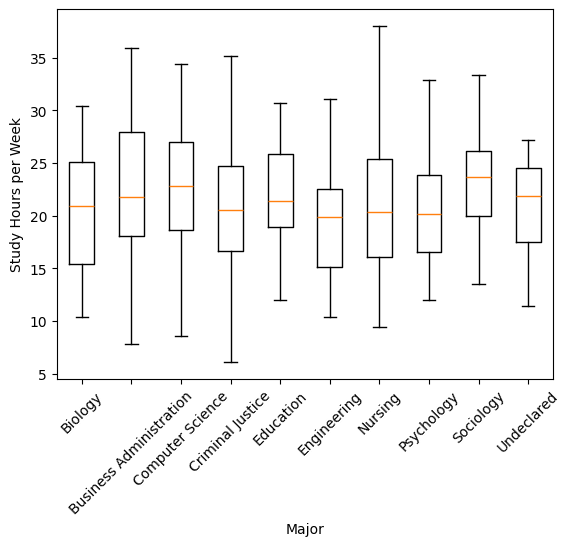

In [64]:
import matplotlib.pyplot as plt

# WORKSHOP INSTRUCTION:

# To visualize a continuous metric (like 'study_hours') across different categories (like 'major'),
# we can group our data and feed individual slices to Matplotlib's boxplot function.
#
# Steps:
# 1) Group the DataFrame by 'major' on our target variable 'study_hours'.
# 2) Use a list comprehension to unpack the data points for each group into a list of arrays.
# 3) Use another list comprehension to extract the unique group names (majors) as tick labels.
# 4) Rotate the labels to prevent overlapping on the plot.

groups = df.groupby('major')['study_hours']

plt.boxplot(
    [values for _, values in groups],
    tick_labels=[major for major, _ in groups]
)

plt.xlabel('Major')
plt.ylabel('Study Hours per Week')
plt.xticks(rotation=45)
plt.show()

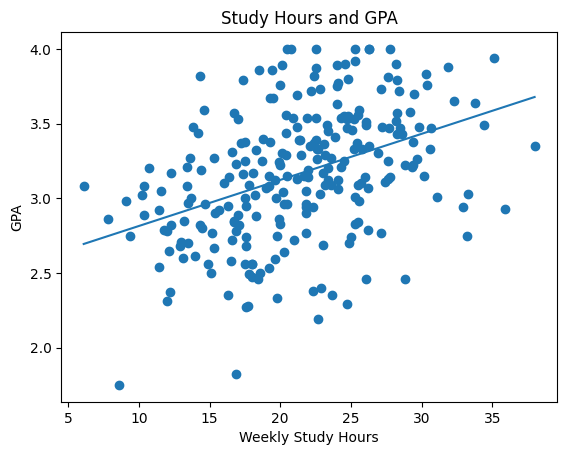

In [70]:
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# WORKSHOP INSTRUCTION:
# This cell visualizes the bivariate relationship between Study Hours and GPA
# by plotting a scatter plot of individual data points and overlaying the regression line.
#
# Code Steps:
# 1) Use plt.scatter() to plot actual data points (study_hours vs. gpa).
# 2) Fit a linear regression model directly inline using Ordinary Least Squares (OLS).
# 3) Sort 'study_hours' so that the line draws smoothly from left to right instead of zig-zagging.
# 4) Predict GPA values using our fitted model and overlay the regression line.

# Plot the scatter points
plt.scatter(df['study_hours'], df['gpa'])

# Fit the regression model directly inline
local_model = smf.ols('gpa ~ study_hours', data=df).fit()

# Sort study hours and plot the regression line
x = df['study_hours'].sort_values()
plt.plot(x, local_model.predict(df.loc[x.index]))

plt.xlabel('Weekly Study Hours')
plt.ylabel('GPA')
plt.title('Study Hours and GPA')
plt.show()

#### Understanding the SciPy library: ##

#### SciPy is the fundamental library for scientific and technical computing in Python.  In functional terms, its specialized submodules are the most important feature and building blocks of the SciPy library. ####

### Now for one final example using the SciPy library to answer a related question.  Rather than building another prediction equation, let's ask whether weekly study hours and GPA are linearly related. ####



In [77]:
from scipy import stats
import pandas as pd
import pyreadstat

# WORKSHOP INSTRUCTION:
# One-Way ANOVA is used to determine whether there are any statistically
# significant differences between the means of three or more independent groups.
#
# Hypotheses under test:
# - Null Hypothesis (H0): The mean GPA is equal across all academic majors (no group differences).
# - Alternative Hypothesis (H1): At least one academic major has a mean GPA that is statistically different from the others.
#
# Code Steps:
# 1) Unpack the pyreadstat tuple (df, meta) using '_' to discard metadata and assign the DataFrame.
# 2) Extract the unique academic majors to represent our group classifications.
# 3) Filter the GPA values for each major into separate arrays, removing any missing values.
# 4) Use stats.f_oneway() to perform the ANOVA test.

# Unpack the SAV tuple to store only the DataFrame in df_anova
df_anova, _ = pyreadstat.read_sav("mwera_student_academic_success_dataset.sav")

# Identify the unique categorical groupings (academic majors) to act as our discrete factors (the categorical independent variable)
majors = df_anova['major'].unique()

# Create a list of GPA values for each major from df_anova
gpa_by_major = [df_anova[df_anova['major'] == major]['gpa'].dropna() for major in majors]

# Perform one-way ANOVA test
f_statistic, p_value = stats.f_oneway(*gpa_by_major)

print(f"F-statistic: {f_statistic}")
print(f"P-value: {p_value}")

# Interpretation
alpha = 0.05

if p_value < alpha:
    print("Reject the null hypothesis.")
    print("There is a statistically significant difference in GPA among different majors.")
else:
    print("Fail to reject the null hypothesis.")
    print("There is no statistically significant difference in GPA among different majors.")

F-statistic: 1.325065477540108
P-value: 0.22439982768093708
Fail to reject the null hypothesis.
There is no statistically significant difference in GPA among different majors.


$$ \widehat{\text{GPA}} = b_0 + b_1(\text{Study Hours}) $$

## Part 5: Simple Linear Regression

### **Workshop Overview & Educational Context**

* **Research Question (RQ):** To what extent do weekly study hours predict college students' current GPA?
* **Data Setup:**
  * **Predictor ($X$):** `study_hours` (Weekly study hours, Numeric)
  * **Outcome ($Y$):** `gpa` (Current GPA, Numeric)

---

### **Analytical Approach: Ordinary Least Squares (OLS)**
We will use the **Statsmodels** library to perform an OLS regression. This method estimates the intercept ($b_0$) and the slope ($b_1$) by finding the line of best fit that minimizes the sum of squared residuals (the differences between actual and predicted GPAs).

In [79]:
# Pyreadstat Import
df, meta = pyreadstat.read_sav("mwera_student_academic_success_dataset.sav")

In [80]:
# Pandas to inspect the two variables
df[['study_hours', 'gpa']].describe()

,study_hours,gpa
count,250.000000,250.000000
mean,21.305600,3.162960
std,5.868065,0.441305
min,6.100000,1.750000
25%,17.400000,2.852500
50%,21.600000,3.165000
75%,25.300000,3.480000
max,38.000000,4.000000


In [81]:
# NumPy gives you the underlying numerical summaries
import numpy as np

np.mean(df['study_hours'])
np.mean(df['gpa'])

np.float64(3.16296)

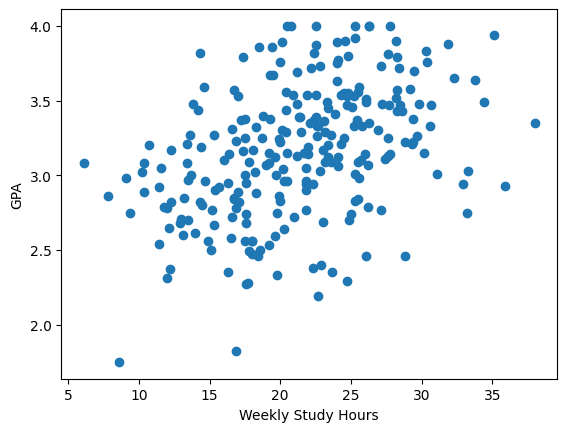

In [82]:
# Matplotlib lets the audience actually see the relationship.
plt.scatter(df['study_hours'], df['gpa'])
plt.xlabel('Weekly Study Hours')
plt.ylabel('GPA')
plt.show()

#### OLS stands for Ordinary Least Squares. It is the estimation method we're using to determine the best-fitting regression line through our data. In our example, we have weekly study hours on the X-axis and GPA on the Y-axis. For every student, there is usually some difference between their actual GPA and the GPA predicted by our regression line. We call that difference a residual. OLS finds the intercept and slope that make the sum of those squared residuals as small as possible. ##

In [83]:
# Statsmodels answers the actual research question:
import statsmodels.formula.api as smf

model = smf.ols('gpa ~ study_hours', data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    gpa   R-squared:                       0.168
Model:                            OLS   Adj. R-squared:                  0.165
Method:                 Least Squares   F-statistic:                     50.18
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           1.44e-11
Time:                        19:39:29   Log-Likelihood:                -126.69
No. Observations:                 250   AIC:                             257.4
Df Residuals:                     248   BIC:                             264.4
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept       2.5056      0.096     26.038      

### **Interpreting the OLS Regression Output**

* **Intercept ($b_0 = 2.506$):** The predicted GPA for a student with zero weekly study hours.
* **Slope Coefficient ($b_1 = 0.031$):** Each additional weekly study hour is associated with a predicted increase of **0.031 points** in GPA.
* **Significance ($p < 0.001$):** Because the $p$-value for `study_hours` is well below the standard threshold ($\\alpha = 0.05$), weekly study hours are a statistically significant predictor of GPA.
* **R-squared ($R^2 = 0.168$):** Study hours account for approximately **16.8%** of the variance in student GPA. The remaining 83.2% is unexplained variance driven by other external variables.
* **95% Confidence Interval ($[0.022, 0.039]$):** We are 95% confident that the true population slope lies between 0.022 and 0.039 GPA points per study hour.

### **Fitted Regression Equation**

$$ \widehat{	ext{GPA}} = 2.5056 + 0.0309(\text{Study Hours}) $$
#### The regression model reveals that weekly study hours are a statistically significant positive predictor of academic performance, where every additional hour spent studying per week is associated with a 0.031-point increase in a student's predicted GPA from a baseline of 2.51.

*(Workshop Note: This equation uses our calculated OLS intercept and slope to predict a student's GPA based on their weekly study hours.)*

---

### **Resources**
* **Library Documentation:**
  * [Statsmodels OLS Regression](https://www.statsmodels.org/stable/regression.html)
  * [Pandas Documentation](https://pandas.pydata.org/docs/)
  * [SciPy Stats Module](https://docs.scipy.org/doc/scipy/reference/stats.html)
* **Workshop Guide:** Refer to the presentation slides for a detailed breakdown of regression diagnostic assumptions (normality, homoscedasticity, and independence).

### Thank You & Closing

### Thank you all for your time, participation, and engagement today. I hope this workshop demonstrated that Python can be an accessible tool for educational and scientific research—not only for working with data, but for transforming data into meaningful evidence.**

### I encourage you to continue experimenting with the techniques we explored today and to think about how Python might complement the research methods and statistical tools you already use.

### Thank you for joining me, and I hope you enjoy the rest of MWERA.